# CBDB comparison with Cultura

Same method as notebook 18 (Treccani), with the China Biographical Database (CBDB) as reference. Individuals are drawn across centuries, from the 3rd to the 20th, and only those whose CBDB window is a range of years are kept: up to 30 per century, taken in the random order of the draw. Most of Wikidata's dates and citizenships of these individuals are themselves referenced to CBDB: no individual is left out, so this is a consistency check between Cultura and CBDB rather than an independent validation. The share of CBDB-sourced statements is shown below.

## Settings

In [1]:
from pathlib import Path
import json

import duckdb
import pandas as pd
import polars as pl

from style import show_table

ROOT = Path.cwd().parent
DATABASE = ROOT / "data" / "cultura" / "humans_clean_enriched_v3.duckdb"
FOLDER = ROOT / "scripts" / "5-annotations" / "cbdb_validation"
SAMPLE = FOLDER / "cbdb_sample.json"
RECORDS = FOLDER / "cbdb_persons.json"
REFERENCES = ROOT / "scripts" / "5-annotations" / "data" / "cbdb_wikidata_references.json"
POSTHUMOUS = {"贈", "追封", "累贈", "卒贈", "追"}
PER_CENTURY = 30

## CBDB window and dynasty

The CBDB window runs from the first to the last year of documented activity: the examination year, the years of each office posting and the years of dated social associations. Posthumous postings (贈, 追封…), unknown years (0 and -1) and years outside the CBDB lifespan are left out. Years given to written works are not used: they often are the year a collection was compiled, after death. Individuals whose CBDB window is a single year, or who have none, are left out.

In [2]:
def rows(record, key):
    value = record.get(key) or {}
    value = next(iter(value.values()), []) if isinstance(value, dict) else []
    return value if isinstance(value, list) else [value]


def year(value):
    value = str(value or "")
    return int(value) if value.isdigit() and int(value) > 0 else None


def activity_years(record):
    born, died = year(record["BasicInfo"]["YearBirth"]), year(record["BasicInfo"]["YearDeath"])
    years = [year(entry["RuShiYear"]) for entry in rows(record, "PersonEntryInfo")]
    years += [year(posting[key]) for posting in rows(record, "PersonPostings") if posting.get("ChuShouType") not in POSTHUMOUS for key in ("FirstYear", "LastYear")]
    years += [year(association["Year"]) for association in rows(record, "PersonSocialAssociation")]
    return [y for y in years if y is not None and (born is None or y >= born) and (died is None or y <= died)]


sample = pd.read_json(SAMPLE)
records = json.loads(RECORDS.read_text(encoding="utf-8"))
sample = sample[sample["qid"].isin(records)]
years = sample["qid"].map(lambda qid: activity_years(records[qid]))
sample["cbdb_dynasty"] = sample["qid"].map(lambda qid: records[qid]["BasicInfo"]["Dynasty"])
sample["cbdb_start"] = years.map(lambda found: min(found) if found else None)
sample["cbdb_end"] = years.map(lambda found: max(found) if found else None)
sample["cbdb_window"] = sample.apply(lambda row: None if pd.isna(row["cbdb_start"]) else f"{int(row['cbdb_start'])}-{int(row['cbdb_end'])}", axis=1)
print(len(sample), "individuals drawn,", sample["cbdb_start"].notna().sum(), "with a CBDB window,", (sample["cbdb_end"] > sample["cbdb_start"]).sum(), "with a range of years")
sample = sample[sample["cbdb_end"] > sample["cbdb_start"]].sort_values(["century", "draw"]).groupby("century").head(PER_CENTURY).reset_index(drop=True)
print(len(sample), "individuals kept, up to", PER_CENTURY, "per century")
sample

9433 individuals drawn, 3499 with a CBDB window, 1321 with a range of years
449 individuals kept, up to 30 per century


,qid,name,cbdb_id,century,draw,cbdb_dynasty,cbdb_start,cbdb_end,cbdb_window
0,Q470091,Cao Huan,30274,3,16,三國魏,260.0,302.0,260-302
1,Q550290,Cao Mao,30273,3,49,三國魏,254.0,260.0,254-260
2,Q77822,Cao Fang,30272,3,53,三國魏,240.0,274.0,240-274
3,Q313333,Cao Pi,30261,3,54,三國魏,220.0,227.0,220-227
4,Q313327,Sun Quan,20609,3,61,三國吳,229.0,252.0,229-252
...,...,...,...,...,...,...,...,...,...
444,Q15910152,Zhao Binglin,84316,20,457,中華民國,1891.0,1895.0,1891-1895
445,Q15911624,Xie Xufan,340526,20,469,清,1898.0,1903.0,1898-1903
446,Q11118481,Yang Sheng,60322,20,489,中華民國,1877.0,1920.0,1877-1920
447,Q6094039,Qian Nengxun,64133,20,538,中華民國,1893.0,1903.0,1893-1903


## Wikidata statements referenced to CBDB

Share of the individuals whose Cultura inputs are referenced to CBDB in Wikidata: the dates the window is built on, and the citizenship and places the polity is built on.

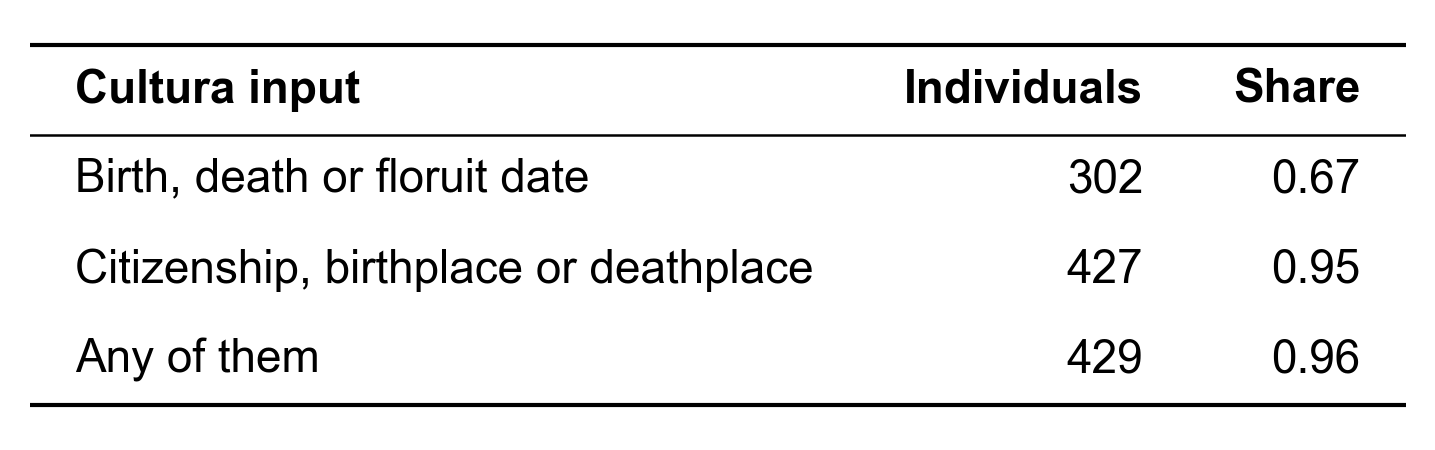

In [3]:
references = pd.DataFrame(json.loads(REFERENCES.read_text(encoding="utf-8")))
from_cbdb = references[references["status"] == "cbdb"]
sample["dates_from_cbdb"] = sample["qid"].isin(from_cbdb[from_cbdb["pid"].isin(["P569", "P570", "P1317"])]["qid"])
sample["places_from_cbdb"] = sample["qid"].isin(from_cbdb[from_cbdb["pid"].isin(["P27", "P19", "P20"])]["qid"])
show_table(pl.DataFrame({
    "Cultura input": ["Birth, death or floruit date", "Citizenship, birthplace or deathplace", "Any of them"],
    "Individuals": [int(sample["dates_from_cbdb"].sum()), int(sample["places_from_cbdb"].sum()), int((sample["dates_from_cbdb"] | sample["places_from_cbdb"]).sum())],
    "Share": [float(sample["dates_from_cbdb"].mean()), float(sample["places_from_cbdb"].mean()), float((sample["dates_from_cbdb"] | sample["places_from_cbdb"]).mean())],
}))

## Cultura window and polities

In [4]:
connection = duckdb.connect(str(DATABASE), read_only=True)
qids = sample["qid"].tolist()

windows = connection.execute("""
    SELECT individual_enriched.entity.qid AS qid,
           individual_enriched.peak_productivity.start_year AS cultura_start,
           individual_enriched.peak_productivity.end_year AS cultura_end
    FROM individual_enriched
    WHERE individual_enriched.entity.qid IN (SELECT unnest(?))
""", [qids]).df()
windows["cultura_window"] = windows.apply(lambda row: f"{int(row['cultura_start'])}-{int(row['cultura_end'])}", axis=1)

polities = connection.execute("""
    SELECT individual_enriched.entity.qid AS qid,
           list(polity_match.polity.name) AS cultura_polity_list,
           string_agg(polity_match.polity.name, ' / ') AS cultura_polities
    FROM individual_enriched, unnest(individual_enriched.polity) AS unnested(polity_match)
    WHERE individual_enriched.entity.qid IN (SELECT unnest(?))
    GROUP BY qid
""", [qids]).df()

cultura = windows.merge(polities, on="qid", how="left")
print(len(cultura), "individuals,", cultura["cultura_polities"].notna().sum(), "with a polity")
cultura

449 individuals, 449 with a polity


,qid,cultura_start,cultura_end,cultura_window,cultura_polity_list,cultura_polities
0,Q1049034,1597,1609,1597-1609,[Ming Dynasty],Ming Dynasty
1,Q15956122,1756,1779,1756-1779,[Qing Dynasty],Qing Dynasty
2,Q45414112,1271,1293,1271-1293,[Mongol Empire],Mongol Empire
3,Q736647,597,630,597-630,[Sui Dynasty],Sui Dynasty
4,Q45643465,604,638,604-638,[Tang Dynasty],Tang Dynasty
...,...,...,...,...,...,...
444,Q15900321,1472,1499,1472-1499,[Ming Dynasty],Ming Dynasty
445,Q45607780,879,897,879-897,[Tang Dynasty],Tang Dynasty
446,Q18906757,595,629,595-629,[Sui Dynasty],Sui Dynasty
447,Q4993,960,969,960-969,[Liao Dynasty],Liao Dynasty


## Comparison table

In [5]:
comparison = sample.merge(cultura, on="qid", how="left")
assert len(comparison) == len(sample)
comparison

,qid,name,cbdb_id,century,draw,cbdb_dynasty,cbdb_start,cbdb_end,cbdb_window,dates_from_cbdb,places_from_cbdb,cultura_start,cultura_end,cultura_window,cultura_polity_list,cultura_polities
0,Q470091,Cao Huan,30274,3,16,三國魏,260.0,302.0,260-302,False,True,260,303,260-303,[Cao Wei],Cao Wei
1,Q550290,Cao Mao,30273,3,49,三國魏,254.0,260.0,254-260,False,True,242,260,242-260,[Cao Wei],Cao Wei
2,Q77822,Cao Fang,30272,3,53,三國魏,240.0,274.0,240-274,False,True,239,274,239-274,[Cao Wei],Cao Wei
3,Q313333,Cao Pi,30261,3,54,三國魏,220.0,227.0,220-227,False,True,219,226,219-226,[Cao Wei],Cao Wei
4,Q313327,Sun Quan,20609,3,61,三國吳,229.0,252.0,229-252,False,False,214,241,214-241,[Eastern Wu],Eastern Wu
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
444,Q15910152,Zhao Binglin,84316,20,457,中華民國,1891.0,1895.0,1891-1895,True,True,1907,1927,1907-1927,[Qing Dynasty],Qing Dynasty
445,Q15911624,Xie Xufan,340526,20,469,清,1898.0,1903.0,1898-1903,False,True,1901,1925,1901-1925,[Qing Dynasty],Qing Dynasty
446,Q11118481,Yang Sheng,60322,20,489,中華民國,1877.0,1920.0,1877-1920,False,True,1904,1930,1904-1930,[Qing Dynasty],Qing Dynasty
447,Q6094039,Qian Nengxun,64133,20,538,中華民國,1893.0,1903.0,1893-1903,False,True,1906,1924,1906-1924,[Qing Dynasty],Qing Dynasty


## Polity accuracy

CBDB gives each individual one dynasty. It is matched to the Cliopatria polities that cover it: Cliopatria splits some dynasties (Song into Northern and Southern Song, Yuan into Mongol Empire then Yuan Dynasty), and has no Eastern Jin, whose territories its Western Jin carries until 425. The polity is correct when one of Cultura's polities is among them. Individuals whose CBDB dynasty is unknown (未詳) are left out.

In [6]:
DYNASTY_POLITIES = {
    "唐": ["Tang Dynasty"], "宋": ["Northern Song", "Southern Song"], "清": ["Qing Dynasty", "Later Jin Dynasty"],
    "明": ["Ming Dynasty", "Southern Ming"], "元": ["Yuan Dynasty", "Mongol Empire"], "北魏": ["Northern Wei"],
    "中華民國": ["Republic of China", "Kuomintang", "Empire of China"], "中華人民共和國": ["People's Republic of China"],
    "東晉": ["Western Jin"], "西晉": ["Western Jin"], "三國魏": ["Cao Wei"], "三國吳": ["Eastern Wu"], "三國蜀": ["Shu Han"],
    "三國": ["Cao Wei", "Eastern Wu", "Shu Han"], "宋(劉)": ["Liu Song Dynasty"], "隋": ["Sui Dynasty"], "南齊": ["Southern Qi"],
    "北周": ["Northern Zhou"], "東漢": ["Han Dynasty"], "後趙": ["Later Zhao"], "西涼": ["Western Liang"], "南梁": ["Liang Dynasty"],
    "南唐": ["Southern Tang"], "遼": ["Liao Dynasty"], "前秦": ["Former Qin"], "後燕": ["Later Yan"], "前涼": ["Former Liang"],
    "北齊": ["Northern Qi"], "金": ["Great Jin"], "後唐": ["Later Tang"], "後秦": ["Later Qin"], "前燕": ["Former Yan"],
    "南北朝": ["Liu Song Dynasty", "Southern Qi", "Liang Dynasty", "Chen Dynasty", "Northern Wei", "Eastern Wei", "Western Wei", "Northern Qi", "Northern Zhou"],
    "陳": ["Chen Dynasty"], "東魏": ["Eastern Wei"], "南漢": ["Southern Han"], "閩國": ["Min"], "高麗": ["Goryeo"],
    "後漢": ["Later Han"], "後蜀": ["Later Shu"], "吳(楊)": ["Southern Wu"],
}
comparison["cbdb_polities"] = comparison["cbdb_dynasty"].map(lambda dynasty: " / ".join(DYNASTY_POLITIES.get(dynasty, [])) or None)
comparison["has_cbdb_polity"] = comparison["cbdb_dynasty"].isin(DYNASTY_POLITIES)
comparison["polity_ok"] = [
    bool(set(DYNASTY_POLITIES.get(dynasty, [])) & set([] if isinstance(found, float) else found))
    for dynasty, found in zip(comparison["cbdb_dynasty"], comparison["cultura_polity_list"])
]
print((~comparison["has_cbdb_polity"]).sum(), "individual(s) without a CBDB dynasty, left out of the polity accuracy")
comparison[["name", "century", "cbdb_dynasty", "cbdb_polities", "cultura_polities", "polity_ok"]]

4 individual(s) without a CBDB dynasty, left out of the polity accuracy


,name,century,cbdb_dynasty,cbdb_polities,cultura_polities,polity_ok
0,Cao Huan,3,三國魏,Cao Wei,Cao Wei,True
1,Cao Mao,3,三國魏,Cao Wei,Cao Wei,True
2,Cao Fang,3,三國魏,Cao Wei,Cao Wei,True
3,Cao Pi,3,三國魏,Cao Wei,Cao Wei,True
4,Sun Quan,3,三國吳,Eastern Wu,Eastern Wu,True
...,...,...,...,...,...,...
444,Zhao Binglin,20,中華民國,Republic of China / Kuomintang / Empire of China,Qing Dynasty,False
445,Xie Xufan,20,清,Qing Dynasty / Later Jin Dynasty,Qing Dynasty,True
446,Yang Sheng,20,中華民國,Republic of China / Kuomintang / Empire of China,Qing Dynasty,False
447,Qian Nengxun,20,中華民國,Republic of China / Kuomintang / Empire of China,Qing Dynasty,False


## Productivity window accuracy

A Cultura window is correct when it covers at least 50% of the CBDB window. Every individual kept has a CBDB window.

In [7]:
overlap = (comparison[["cbdb_end", "cultura_end"]].min(axis=1, skipna=False) - comparison[["cbdb_start", "cultura_start"]].max(axis=1, skipna=False) + 1).clip(lower=0)
cbdb_span = comparison["cbdb_end"] - comparison["cbdb_start"] + 1
comparison["overlap_years"] = overlap
comparison["overlap_share"] = (overlap / cbdb_span).round(2)
comparison["window_ok"] = comparison["overlap_share"].fillna(0) >= 0.5
comparison["has_cbdb_window"] = comparison["cbdb_start"].notna()
print((~comparison["has_cbdb_window"]).sum(), "individual(s) without a CBDB window, left out of the window accuracy")
comparison[["name", "century", "cbdb_window", "cultura_window", "overlap_years", "overlap_share", "window_ok"]]

0 individual(s) without a CBDB window, left out of the window accuracy


,name,century,cbdb_window,cultura_window,overlap_years,overlap_share,window_ok
0,Cao Huan,3,260-302,260-303,43.0,1.00,True
1,Cao Mao,3,254-260,242-260,7.0,1.00,True
2,Cao Fang,3,240-274,239-274,35.0,1.00,True
3,Cao Pi,3,220-227,219-226,7.0,0.88,True
4,Sun Quan,3,229-252,214-241,13.0,0.54,True
...,...,...,...,...,...,...,...
444,Zhao Binglin,20,1891-1895,1907-1927,0.0,0.00,False
445,Xie Xufan,20,1898-1903,1901-1925,3.0,0.50,True
446,Yang Sheng,20,1877-1920,1904-1930,17.0,0.39,False
447,Qian Nengxun,20,1893-1903,1906-1924,0.0,0.00,False


## Accuracy of Cultura against CBDB

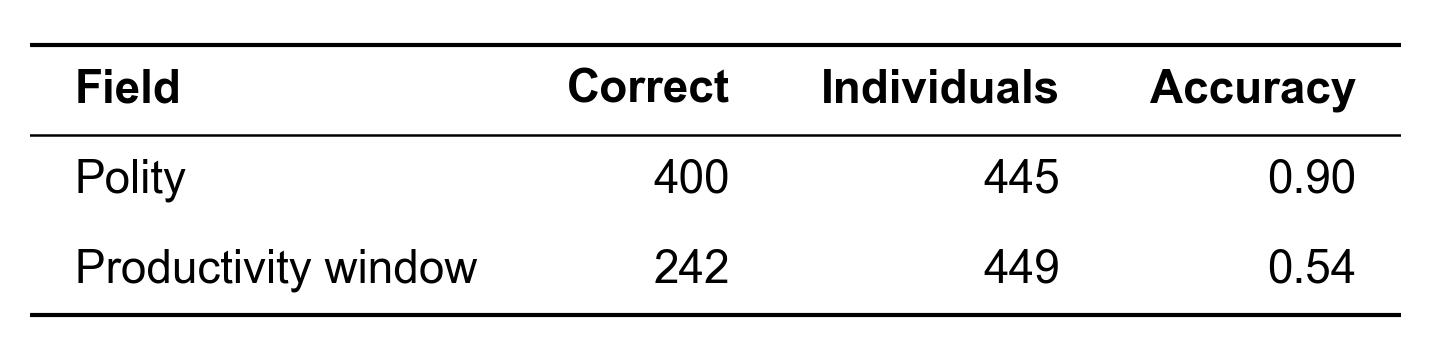

In [8]:
polity_rows = comparison[comparison["has_cbdb_polity"]]
window_rows = comparison[comparison["has_cbdb_window"]]
show_table(pl.DataFrame({
    "Field": ["Polity", "Productivity window"],
    "Correct": [int(polity_rows["polity_ok"].sum()), int(window_rows["window_ok"].sum())],
    "Individuals": [len(polity_rows), len(window_rows)],
    "Accuracy": [float(polity_rows["polity_ok"].mean()), float(window_rows["window_ok"].mean())],
}))

## Productivity window accuracy by overlap threshold

Share of individuals whose Cultura window covers at least the given share of the CBDB window.

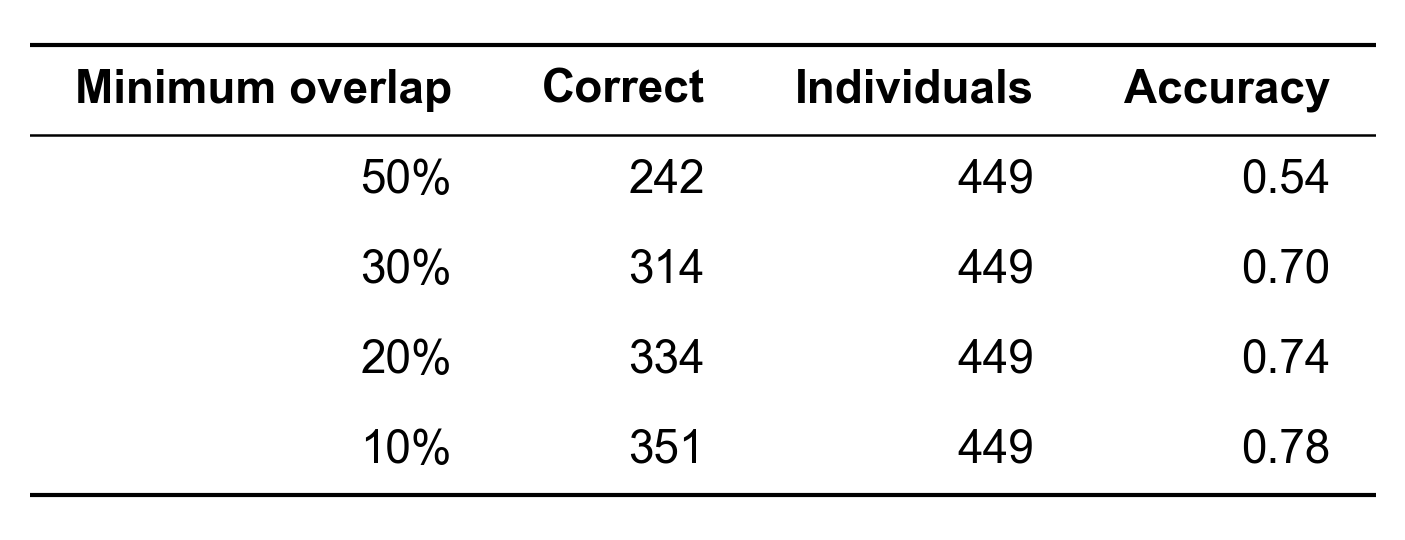

In [9]:
thresholds = [0.5, 0.3, 0.2, 0.1]
window_shares = window_rows["overlap_share"].fillna(0)
show_table(pl.DataFrame({
    "Minimum overlap": [f"{threshold:.0%}" for threshold in thresholds],
    "Correct": [int((window_shares >= threshold).sum()) for threshold in thresholds],
    "Individuals": [len(window_rows)] * len(thresholds),
    "Accuracy": [float((window_shares >= threshold).mean()) for threshold in thresholds],
}))

## Accuracy by century

Century of the start of the Cultura window. A dash marks a century with no individual to judge.

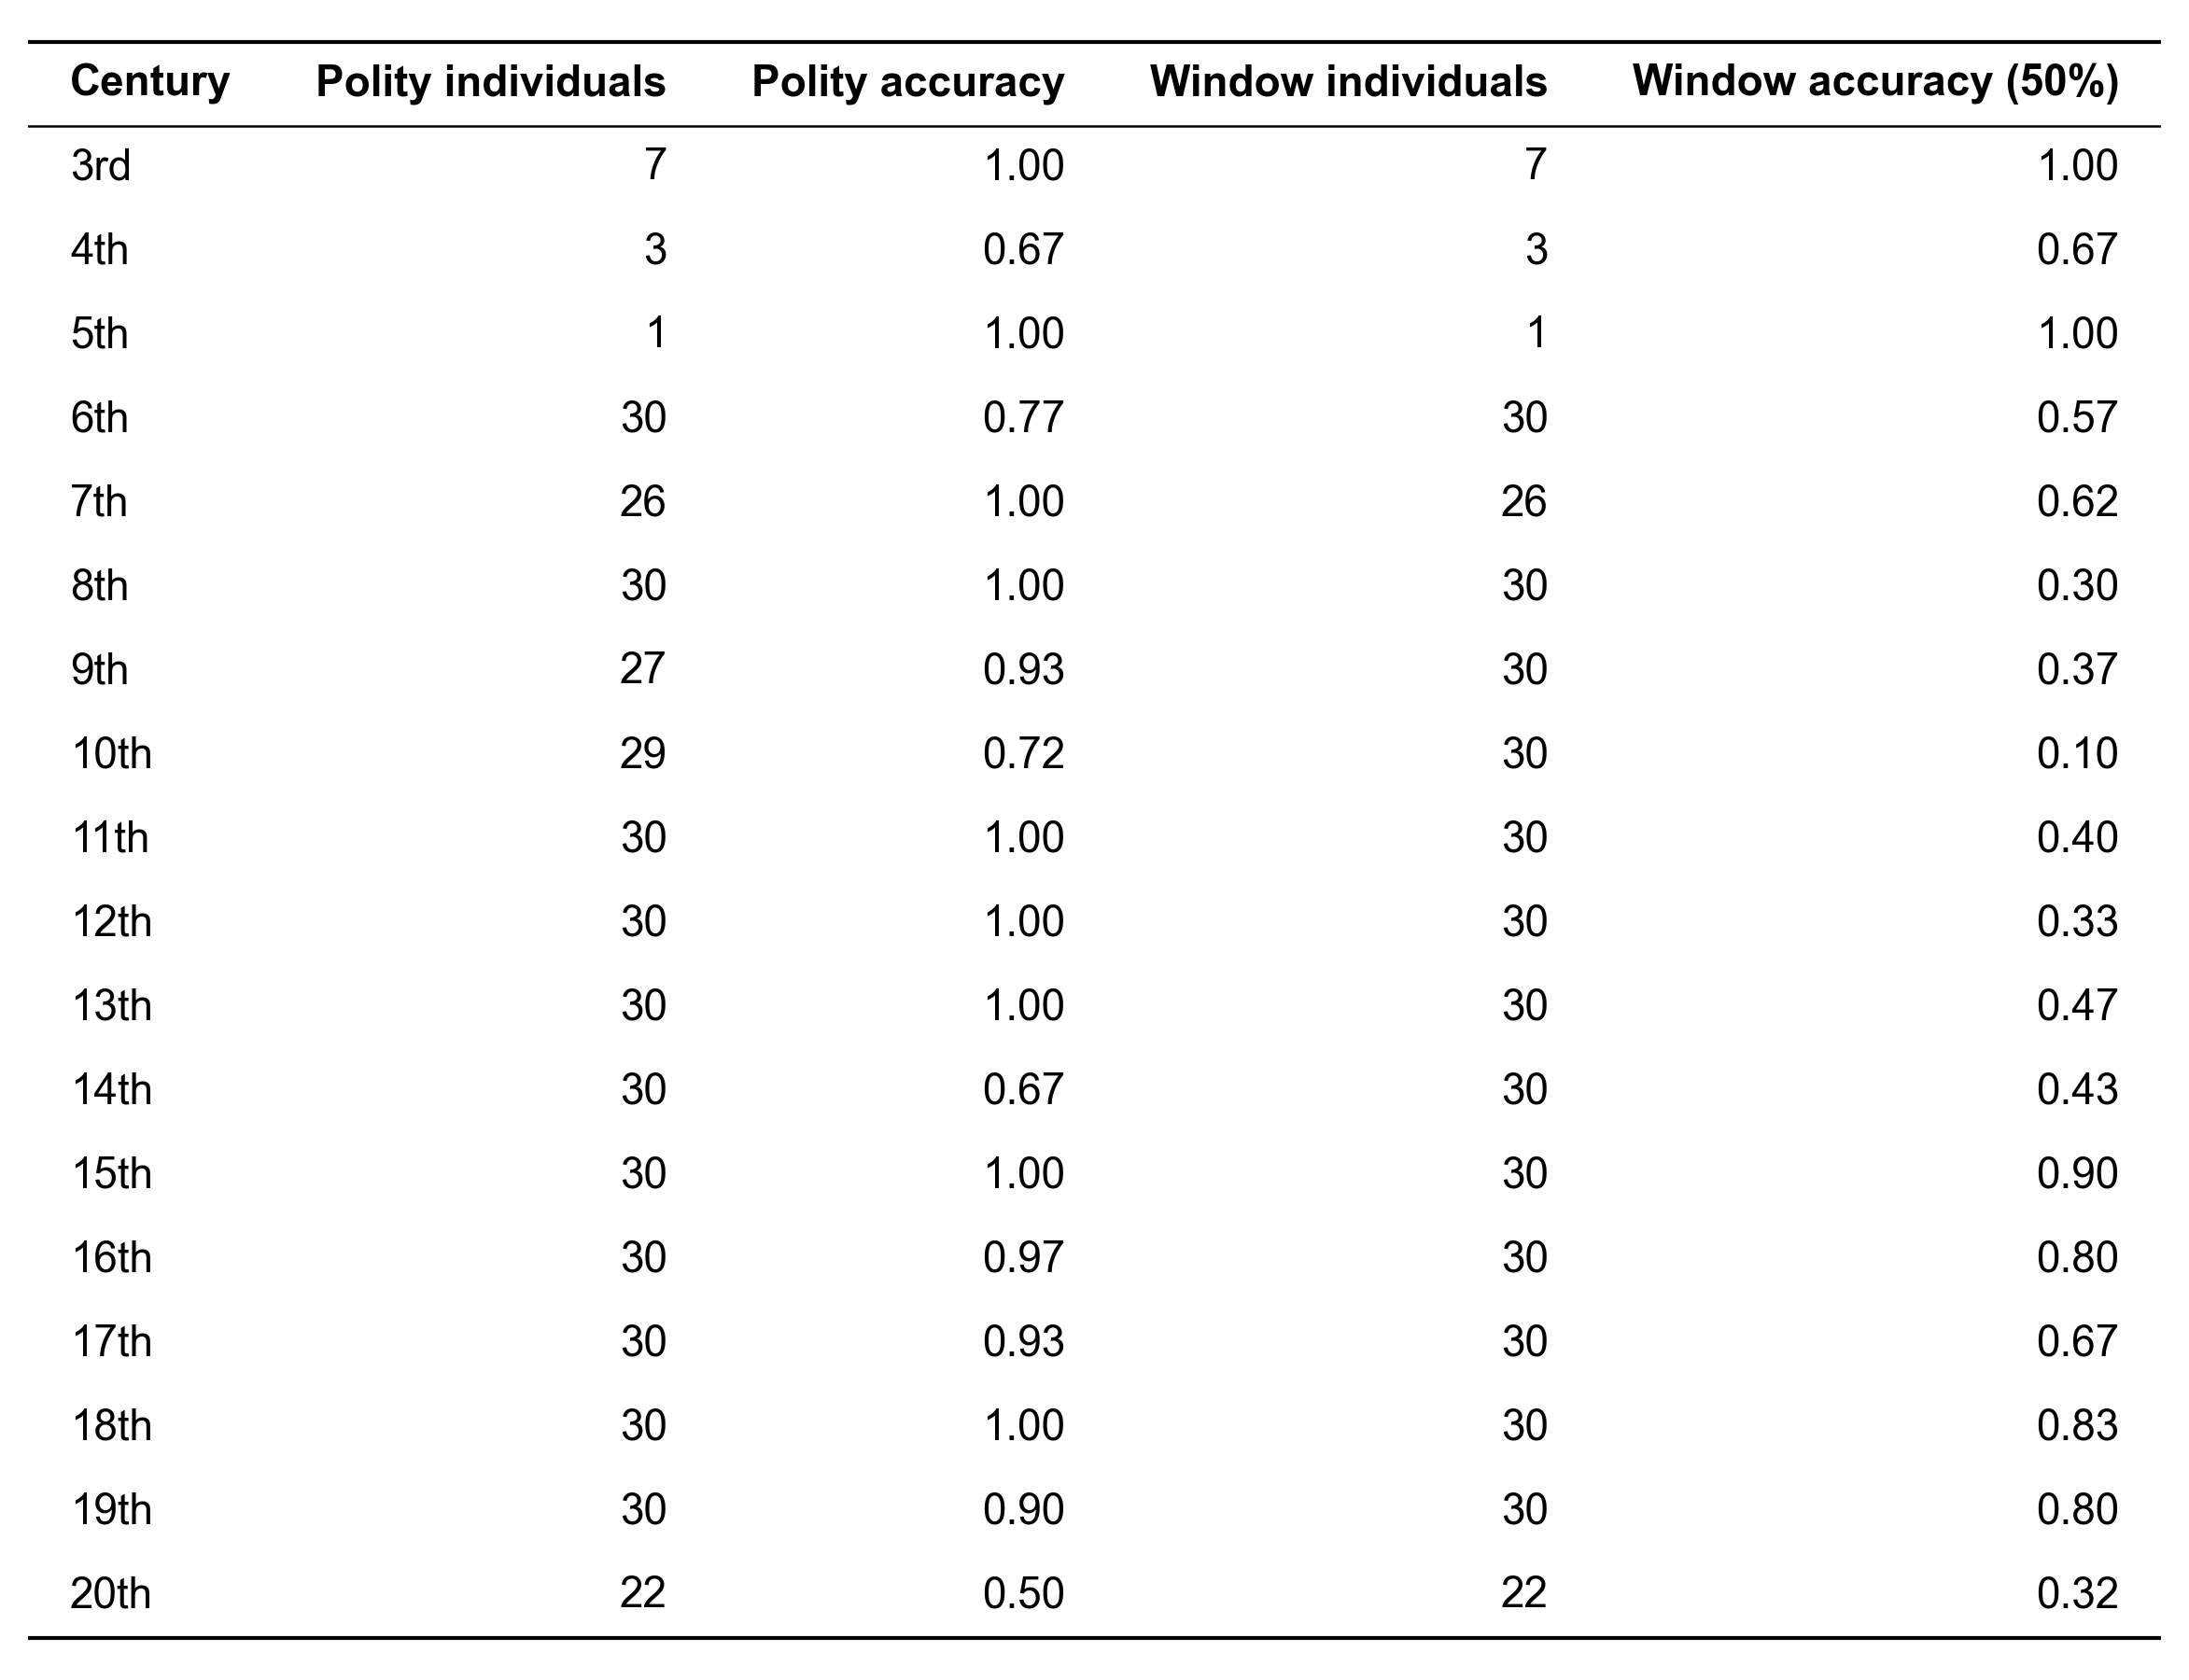

In [10]:
by_century = pd.DataFrame({
    "polity_n": polity_rows.groupby("century").size(),
    "polity_accuracy": polity_rows.groupby("century")["polity_ok"].mean(),
    "window_n": window_rows.groupby("century").size(),
    "window_accuracy": window_rows.groupby("century")["window_ok"].mean(),
}).reindex(sorted(comparison["century"].unique()))
show_table(pl.DataFrame({
    "Century": [f"{century}{'rd' if century == 3 else 'th'}" for century in by_century.index],
    "Polity individuals": [None if pd.isna(n) else int(n) for n in by_century["polity_n"]],
    "Polity accuracy": [None if pd.isna(a) else float(a) for a in by_century["polity_accuracy"]],
    "Window individuals": [None if pd.isna(n) else int(n) for n in by_century["window_n"]],
    "Window accuracy (50%)": [None if pd.isna(a) else float(a) for a in by_century["window_accuracy"]],
}))

## Accuracy by CBDB sourcing

The same accuracies, split by whether the Cultura inputs are referenced to CBDB in Wikidata: the dates for the window, the citizenship and places for the polity.

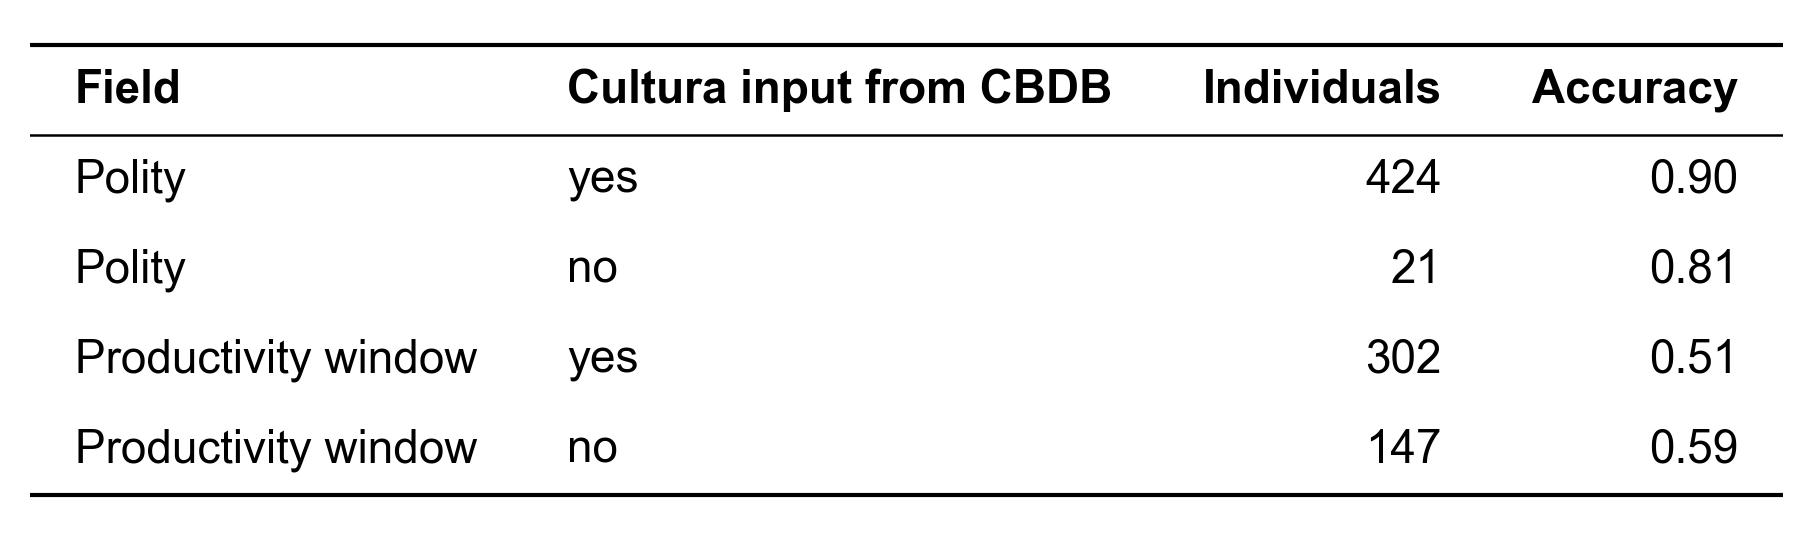

In [11]:
show_table(pl.DataFrame({
    "Field": ["Polity", "Polity", "Productivity window", "Productivity window"],
    "Cultura input from CBDB": ["yes", "no", "yes", "no"],
    "Individuals": [int(polity_rows["places_from_cbdb"].sum()), int((~polity_rows["places_from_cbdb"]).sum()),
                    int(window_rows["dates_from_cbdb"].sum()), int((~window_rows["dates_from_cbdb"]).sum())],
    "Accuracy": [float(polity_rows[polity_rows["places_from_cbdb"]]["polity_ok"].mean()), float(polity_rows[~polity_rows["places_from_cbdb"]]["polity_ok"].mean()),
                 float(window_rows[window_rows["dates_from_cbdb"]]["window_ok"].mean()), float(window_rows[~window_rows["dates_from_cbdb"]]["window_ok"].mean())],
}))